# Explore the mock EMR data

Look at the data **before** modelling. This notebook answers:

1. What is one row? What columns are there, and what's missing?
2. How common is the outcome, and how does it vary by month, region, age and sex?
3. What does the MUAC vs WHZ relationship look like (and why does it matter for fairness)?
4. What do the drift / data-quality scenarios look like next to normal data?

Everything here is **synthetic** (see `README.md` in this folder). Run cells top to bottom;
if anything looks odd, use *Restart & Run All*.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, PercentFormatter

DATA = Path("data")          # scratch folder next to this notebook (gitignored)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})


def simulate(start, months=1, scenario="baseline"):
    """Run the simulator (same as the command line) into its own folder under data/."""
    out = DATA / f"{scenario}_{start}_{months}m"
    subprocess.run([sys.executable, "simulate_emr.py", "--start", start, "--months", str(months),
                    "--scenario", scenario, "--out", str(out)], check=True, capture_output=True)
    return pd.concat(pd.read_csv(f) for f in sorted(out.glob("emr_*.csv")))


df = simulate("2024-01", months=12)   # one year of normal data, 2000 visits per month
df["month"] = df["visit_date"].str[:7]
df["age_band"] = pd.cut(df["age_months"], [-1, 5, 23, 59], labels=["0-5m", "6-23m", "24-59m"])
df.shape

(24000, 25)

## 1. What is one row?

One **visit** by a child aged 0-59 months who is *not currently* acutely malnourished.
The label `gam_within_90d` says whether they developed acute malnutrition within 90 days.

In [2]:
df.head(3).T

,0,1,2
visit_id,V202401-00000,V202401-00001,V202401-00002
child_id,C7883078,C1765073,C5479400
visit_date,2024-01-01,2024-01-01,2024-01-01
facility_id,TI-HC5,AA-HC5,AM-HC3
region,Tigray,Addis Ababa,Amhara
residence,rural,urban,rural
sex,M,F,F
age_months,24,2,22
weight_kg,10.4,3.9,8.5
height_cm,80.3,54.3,76.1


In [3]:
# Missing values: only MUAC, and only because it isn't measured under 6 months
missing = df.isna().mean().loc[lambda s: s > 0]
print(missing.round(3))
print("share of under-6-month visits:", round((df["age_months"] < 6).mean(), 3))

muac_cm    0.196
dtype: float64
share of under-6-month visits: 0.196


In [4]:
df.describe().T[["mean", "min", "50%", "max"]].round(2)

,mean,min,50%,max
age_months,19.03,0.0,16.00,59.0
weight_kg,9.06,1.7,9.10,23.2
height_cm,74.53,38.6,74.70,118.0
whz,-0.33,-2.0,-0.39,3.7
muac_cm,13.69,12.5,13.60,16.9
recent_diarrhea,0.20,0.0,0.00,1.0
recent_fever,0.18,0.0,0.00,1.0
vaccinated_for_age,0.68,0.0,1.00,1.0
currently_breastfed,0.65,0.0,1.00,1.0
prior_sam_admission,0.05,0.0,0.00,1.0


## 2. How common is the outcome?

About 1 visit in 9 leads to acute malnutrition within 90 days. That's an **imbalanced**
label: a model that always says "no" is ~89% accurate and completely useless.
This is why the DVC lesson reports sensitivity and PPV, not accuracy.

overall rate: 11.0%


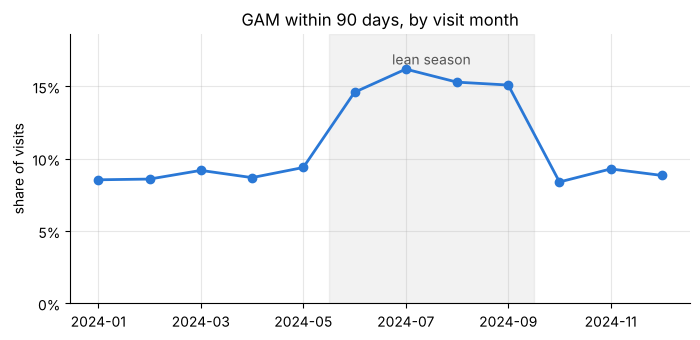

In [5]:
print(f"overall rate: {df['gam_within_90d'].mean():.1%}")

monthly = df.groupby("month")["gam_within_90d"].mean()
ax = monthly.plot(marker="o", color=BLUE, linewidth=2, markersize=6)
ax.axvspan(4.5, 8.5, color="#999999", alpha=0.12)             # Jun-Sep
ax.text(6.5, monthly.max() * 1.02, "lean season", ha="center", color="#555555")
ax.set(title="GAM within 90 days, by visit month", xlabel="", ylabel="share of visits",
       ylim=(0, monthly.max() * 1.15))
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
plt.show()

**The lean season (June-September) nearly doubles the rate.** Remember this when a
model trained on Jan-Apr is tested on May-Jun (the DVC lesson's v1): the test set is
harder *and* has more cases than training.

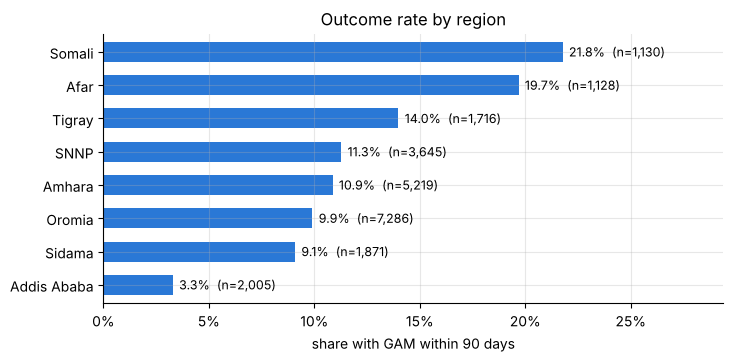

In [6]:
def rate_bars(col, title):
    """Horizontal bars of the outcome rate per group, labelled with rate and visit count."""
    g = df.groupby(col, observed=True)["gam_within_90d"].agg(["mean", "size"]).sort_values("mean")
    ax = g["mean"].plot.barh(color=BLUE, width=0.6)
    for i, (rate, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(rate + 0.003, i, f"{rate:.1%}  (n={n:,})", va="center", fontsize=9)
    ax.set(title=title, xlabel="share with GAM within 90 days", ylabel="", xlim=(0, g["mean"].max() * 1.35))
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    plt.show()

rate_bars("region", "Outcome rate by region")

Pastoralist regions (Afar, Somali) have roughly 6x the rate of Addis Ababa, and far fewer
visits. A single risk threshold will flag almost nobody in Addis, which you'll see in
`metrics_by_group.json` and come back to in the Fairlearn lesson.

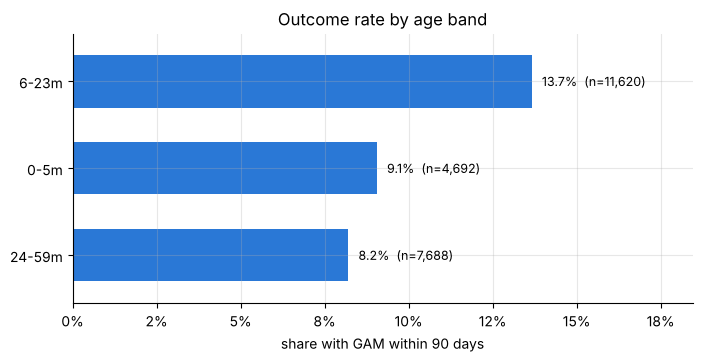

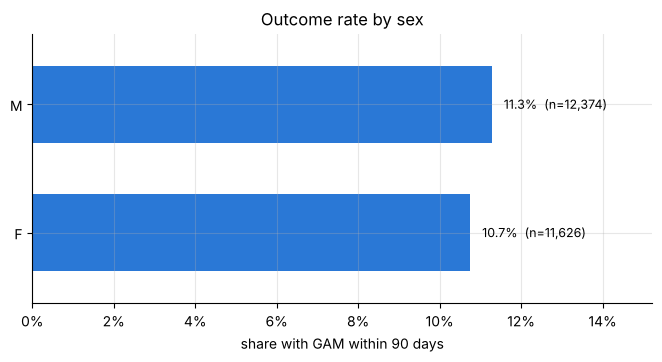

In [7]:
rate_bars("age_band", "Outcome rate by age band")
rate_bars("sex", "Outcome rate by sex")

Children aged 6-23 months (weaning age) are the riskiest. The rate is nearly the same for
girls and boys, but the model still catches fewer girls (sensitivity 0.53 vs 0.60).
The next plot shows one reason.

## 3. MUAC vs WHZ: same child, two measurements

Field programmes use two definitions of acute malnutrition: MUAC (arm circumference) and
WHZ (weight-for-height z-score). They disagree, and **not equally for everyone**. In this
simulator (as in field studies), girls have a lower MUAC at the same WHZ.

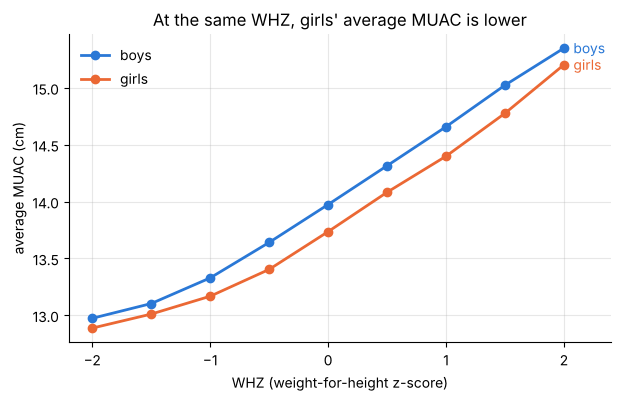

average gap at the same WHZ: 0.19 cm (boys higher)


In [8]:
# Average MUAC within half-unit WHZ bins, separately for girls and boys
m = df.dropna(subset=["muac_cm"]).copy()
m["whz_bin"] = (m["whz"] * 2).round() / 2                    # -2.0, -1.5, ..., 2.0
binned = (m[m["whz_bin"].between(-2, 2)]
          .groupby(["whz_bin", "sex"])["muac_cm"].mean().unstack())

fig, ax = plt.subplots(figsize=(7, 4))
for sex, color, name in [("M", BLUE, "boys"), ("F", ORANGE, "girls")]:
    ax.plot(binned.index, binned[sex], marker="o", color=color, linewidth=2, markersize=6, label=name)
    ax.text(2.08, binned[sex].iloc[-1], name, color=color, va="center", fontsize=10)
ax.set(xlabel="WHZ (weight-for-height z-score)", ylabel="average MUAC (cm)",
       title="At the same WHZ, girls' average MUAC is lower", xlim=(-2.2, 2.4))
ax.legend(frameon=False, loc="upper left")
plt.show()

gap = (binned["M"] - binned["F"]).mean()
print(f"average gap at the same WHZ: {gap:.2f} cm (boys higher)")

If the outcome label partly depends on MUAC, girls cross the line differently from boys
for the same underlying nutrition. **The definition of the label itself differs by group**,
before any model is involved. Keep this in mind for the Fairlearn lesson.

## 4. What do the scenarios look like?

Generate one month of each scenario and compare with normal data.

In [9]:
scenarios = {s: simulate("2025-01", scenario=s)
             for s in ["baseline", "new_regions", "muac_mm", "missing_anthro", "messy_export"]}

summary = pd.DataFrame({
    s: {"visits": len(d),
        "GAM rate": round(d["gam_within_90d"].mean(), 3),
        "Afar+Somali share": round(d["region"].isin(["Afar", "Somali"]).mean(), 3),
        "MUAC median": d["muac_cm"].median(),
        "weight missing": round(d["weight_kg"].isna().mean(), 3),
        "duplicate visit_ids": int(d["visit_id"].duplicated().sum()),
        "sex codes": ", ".join(sorted(d["sex"].unique()))}
    for s, d in scenarios.items()})
summary

,baseline,new_regions,muac_mm,missing_anthro,messy_export
visits,2000,2000,2000,2000,2015
GAM rate,0.082,0.118,0.082,0.082,0.081
Afar+Somali share,0.094,0.502,0.094,0.094,0.093
MUAC median,13.6,13.6,136.0,13.6,14.0
weight missing,0.0,0.0,0.0,0.703,0.0
duplicate visit_ids,0,0,0,0,15
sex codes,"F, M","F, M","F, M","F, M","F, M, female, male"


Read the table column by column:

- **new_regions**: every value is valid, but Afar+Somali jump from ~10% to ~50% of visits
  and the GAM rate rises. *Valid but different* - drift (Evidently lesson).
- **muac_mm**: MUAC median ~137 instead of ~13.7. *Broken* - units (Great Expectations).
- **missing_anthro**: 70% of weights missing (Great Expectations).
- **messy_export**: duplicates, `female`/`male` codes, and more. The MUAC median barely
  moves (13.6 -> 14.0) because only one region is in mm: a summary statistic hides it.

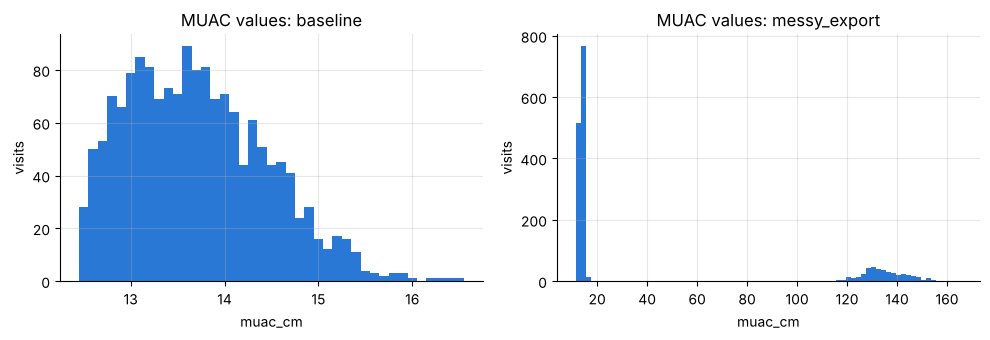

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, ["baseline", "messy_export"]):
    values = scenarios[name]["muac_cm"].dropna()
    step = 0.1 if values.max() < 30 else 2        # MUAC is recorded to 0.1 cm (or whole mm)
    values.plot.hist(bins=np.arange(values.min() - step / 2, values.max() + step, step), ax=ax, color=BLUE)
    ax.set(title=f"MUAC values: {name}", xlabel="muac_cm", ylabel="visits")
plt.tight_layout()
plt.show()

The second cluster near 120-160 is Amhara's facilities recording millimetres. A
row-level check (*every value between 8 and 25 cm*) catches it; an average does not.

### Questions to discuss
1. Which columns would you never use as model features, and why? (`visit_id`, `child_id`, ...)
2. The label is only known 90 days after a visit. What does that mean for how quickly
   we can detect that the model has stopped working?
3. Which of these problems would you rather catch at the EMR export, and which in the ML pipeline?